# Sales dataset by Tesco Supermarkets with over 3400 stores in Europe.

Link: http://kaggle.com/datasets/braniac2000/retail-dataset 


Data Dictionary
Order ID: A unique ID given to each order placed.

Order Date: The date at which the order was placed.

Customer Name: Name of the customer placing the order.

Country: The country to which the customer belongs to.

State: The state to which the customer belongs from the country.

City:Detail about the city to which the customer resides in.

Region: Contains the region details.

Segment:The ordered product belongs to what segment.

Ship Mode: The mode of shipping of the order to the customer location.

Category: Contains the details about what category the product belongs to.

Sub : Category: Contains the details about what sub - category the product belongs to.

Product Name:The name of the product ordered by the customer.

Discount: The discount applicable on a product.

Sales: The actual sales happened for a particular order.

Profit: Profit earned on an order.

Quantity:The total quantity of the product ordered in a single order.

Feedback: The feedback given by the customer on the complete shopping experience. If feedback provided, then TRUE. If no feedback provided, then FALSE.



In [ ]:
# Basic Libraries
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_excel(
    "/Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/Data/Capstone1C_EuroMart Stores-1.xlsx",
    sheet_name="Order Data"
)
df.head()

,Order ID,Order Date,Customer Name,Country,State,City,Region,Segment,Ship Mode,Category,Sub-Category,Product Name,Discount,Sales,Profit,Quantity,Feedback?
0,BN-2011-7407039,2011-01-01,Ruby Patel,Sweden,Stockholm,Stockholm,North,Home Office,Economy Plus,Office Supplies,Paper,"Enermax Note Cards, Premium",0.5,45,-26,3,False
1,AZ-2011-9050313,2011-01-03,Summer Hayward,United Kingdom,England,Southport,North,Consumer,Economy,Furniture,Bookcases,"Dania Corner Shelving, Traditional",0.0,854,290,7,True
2,AZ-2011-6674300,2011-01-04,Devin Huddleston,France,Auvergne-Rhône-Alpes,Valence,Central,Consumer,Economy,Office Supplies,Art,"Binney & Smith Sketch Pad, Easy-Erase",0.0,140,21,3,True
3,BN-2011-2819714,2011-01-04,Mary Parker,United Kingdom,England,Birmingham,North,Corporate,Economy,Office Supplies,Art,"Boston Markers, Easy-Erase",0.5,27,-22,2,True
4,BN-2011-2819714,2011-01-04,Mary Parker,United Kingdom,England,Birmingham,North,Corporate,Economy,Office Supplies,Storage,"Eldon Folders, Single Width",0.5,17,-1,2,True


In [ ]:
print("Data type : ", type(df))
print("Data dims : ", df.shape)

Data type :  <class 'pandas.DataFrame'>
Data dims :  (8047, 17)


In [ ]:
#information of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8047 entries, 0 to 8046
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       8047 non-null   str           
 1   Order Date     8047 non-null   datetime64[us]
 2   Customer Name  8047 non-null   str           
 3   Country        8047 non-null   str           
 4   State          8047 non-null   str           
 5   City           8047 non-null   str           
 6   Region         8047 non-null   str           
 7   Segment        8047 non-null   str           
 8   Ship Mode      8047 non-null   str           
 9   Category       8047 non-null   str           
 10  Sub-Category   8047 non-null   str           
 11  Product Name   8047 non-null   str           
 12  Discount       8047 non-null   float64       
 13  Sales          8047 non-null   int64         
 14  Profit         8047 non-null   int64         
 15  Quantity       8047 non-null   i

In [ ]:
# unique value of each column
df.nunique()

Order ID         4117
Order Date       1214
Customer Name     792
Country            15
State             127
City              999
Region              3
Segment             3
Ship Mode           4
Category            3
Sub-Category       17
Product Name     1810
Discount           14
Sales            1248
Profit            845
Quantity           14
Feedback?           2
dtype: int64

In [ ]:
df.isnull().sum()

Order ID         0
Order Date       0
Customer Name    0
Country          0
State            0
City             0
Region           0
Segment          0
Ship Mode        0
Category         0
Sub-Category     0
Product Name     0
Discount         0
Sales            0
Profit           0
Quantity         0
Feedback?        0
dtype: int64

In [ ]:
df.duplicated().sum()
df[df.duplicated(keep=False)]

,Order ID,Order Date,Customer Name,Country,State,City,Region,Segment,Ship Mode,Category,Sub-Category,Product Name,Discount,Sales,Profit,Quantity,Feedback?
2542,AZ-2012-5907386,2012-08-29,Louie Knight,Belgium,Antwerp,Mechelen,Central,Consumer,Economy,Office Supplies,Art,"Sanford Pens, Fluorescent",0.0,37,10,3,False
2543,AZ-2012-5907386,2012-08-29,Louie Knight,Belgium,Antwerp,Mechelen,Central,Consumer,Economy,Office Supplies,Art,"Sanford Pens, Fluorescent",0.0,37,10,3,False
4065,AZ-2013-5637964,2013-06-14,Cynthia Zielinski,Spain,Madrid,Madrid,South,Home Office,Economy,Office Supplies,Binders,"Wilson Jones 3-Hole Punch, Economy",0.0,84,28,3,True
4066,AZ-2013-5637964,2013-06-14,Cynthia Zielinski,Spain,Madrid,Madrid,South,Home Office,Economy,Office Supplies,Binders,"Wilson Jones 3-Hole Punch, Economy",0.0,84,28,3,True


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)  # should now show 8045 rows instead of 8047

(8045, 17)


In [ ]:
## Numeric Sanity Checks 


          Discount        Sales       Profit     Quantity
count  8045.000000  8045.000000  8045.000000  8045.000000
mean      0.110075   291.903170    35.202237     3.772281
std       0.181787   485.258616   178.147747     2.203610
min       0.000000     3.000000 -3060.000000     1.000000
25%       0.000000    48.000000     1.000000     2.000000
50%       0.000000   117.000000    14.000000     3.000000
75%       0.100000   313.000000    47.000000     5.000000
max       0.850000  6517.000000  2476.000000    14.000000


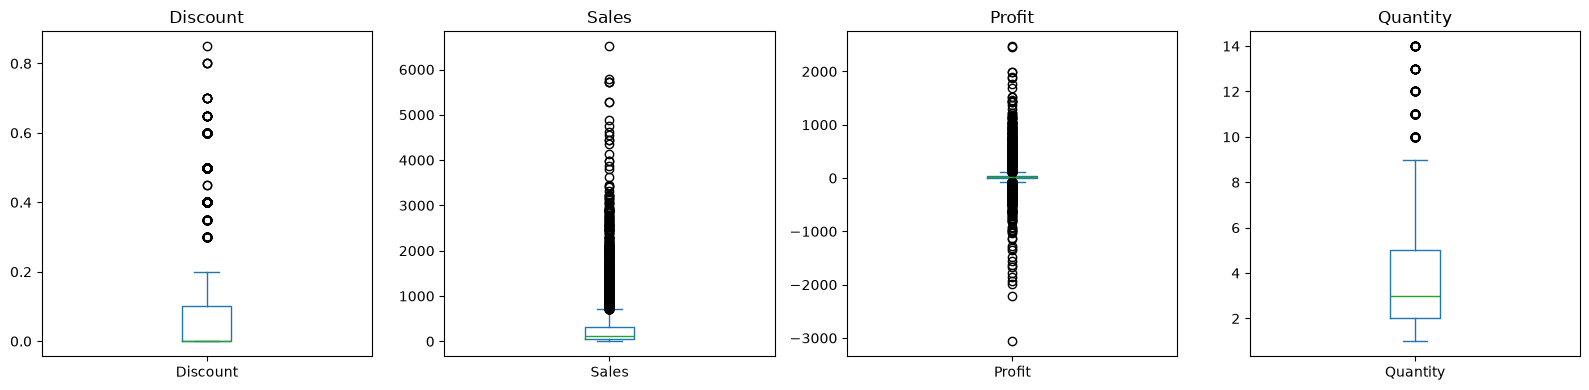

In [ ]:
print(df[['Discount','Sales','Profit','Quantity']].describe())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, col in zip(axes, ['Discount','Sales','Profit','Quantity']):
    df[col].plot(kind='box', ax=ax, title=col)
plt.tight_layout()
plt.show()

Geographic hierarchy consistency

In [ ]:
print(df.groupby('City')['State'].nunique().value_counts())
print(df.groupby('State')['Country'].nunique().value_counts())

State
1    997
2      2
Name: count, dtype: int64
Country
1    126
2      1
Name: count, dtype: int64


In [ ]:
city_issue = df.groupby('City')['State'].nunique()
print(city_issue[city_issue > 1])

state_issue = df.groupby('State')['Country'].nunique()
print(state_issue[state_issue > 1])

City
Halle     2
Langen    2
Name: State, dtype: int64
State
Limburg    2
Name: Country, dtype: int64


To assess the reliability of the geographic columns before using them as node or edge features, a hierarchical consistency check was performed between City, State, and Country. Of the 999 unique cities in the dataset, 997 (99.8%) map to exactly one state, with only 2 cities associated with more than one state. Similarly, of the 127 unique states, 126 (99.2%) map to exactly one country, with only a single state appearing under two different countries. This near-total consistency (over 99% clean in both checks) indicates that the geographic hierarchy in this dataset reflects genuine, stable real-world relationships rather than randomly or inconsistently assigned values. The small number of exceptions is most plausibly explained by legitimate naming coincidences, where the same city or state name exists in more than one country or region, rather than by systematic data quality issues. On this basis, Country, State, City, and Region can be treated as reliable categorical features for downstream analysis and graph construction, without the need for further correction or exclusion.

## Do Order_ID Signal anything

In [ ]:
df['order_prefix'] = df['Order ID'].str.split('-').str[0]
print(df['order_prefix'].value_counts())
print(df.groupby('order_prefix')['Region'].nunique())

order_prefix
AZ    6218
BN    1827
Name: count, dtype: int64
order_prefix
AZ    3
BN    3
Name: Region, dtype: int64


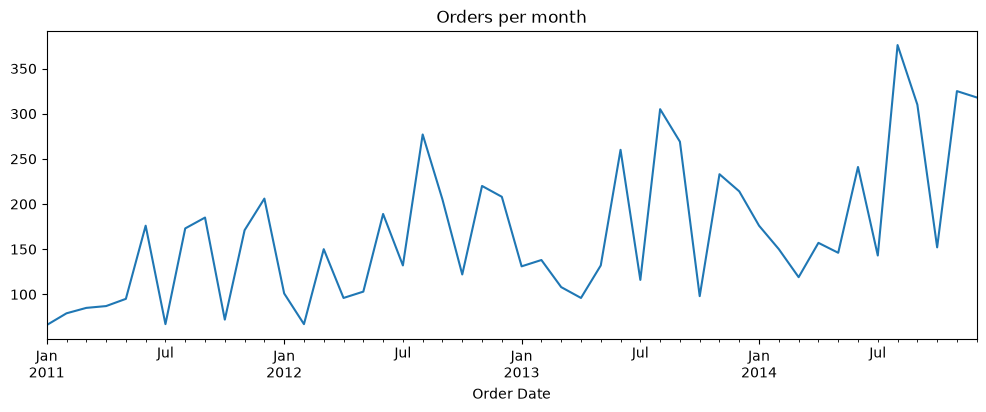

In [ ]:
df.set_index('Order Date').resample('ME').size().plot(figsize=(12,4), title='Orders per month')
plt.show()

In [ ]:
product_features = df.groupby('Product Name').agg(
    category=('Category', 'first'),
    sub_category=('Sub-Category', 'first'),
    times_ordered=('Order ID', 'nunique'),
    total_qty=('Quantity', 'sum'),
    avg_sales=('Sales', 'mean'),
    avg_profit=('Profit', 'mean'),
    avg_discount=('Discount', 'mean'),
    feedback_rate=('Feedback?', 'mean'),
)
product_features.describe(include='all')

,category,sub_category,times_ordered,total_qty,avg_sales,avg_profit,avg_discount,feedback_rate
count,1810,1810,1810.000000,1810.000000,1810.000000,1810.000000,1810.000000,1810.000000
unique,3,17,NaN,NaN,NaN,NaN,NaN,NaN
top,Office Supplies,Binders,NaN,NaN,NaN,NaN,NaN,NaN
freq,984,116,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,4.443094,16.766851,353.232312,33.568248,0.119361,0.497652
std,NaN,NaN,3.326082,13.456348,479.744167,174.838912,0.130364,0.306866
min,NaN,NaN,1.000000,1.000000,7.500000,-1925.000000,0.000000,0.000000
25%,NaN,NaN,2.000000,7.000000,63.270833,0.666667,0.000000,0.333333
50%,NaN,NaN,4.000000,13.000000,156.250000,14.066667,0.100000,0.500000
75%,NaN,NaN,6.000000,22.000000,430.700000,51.916667,0.175000,0.666667


## Dropping Outliers

In [ ]:
def iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

for col in ['Discount', 'Sales', 'Profit', 'Quantity']:
    mask, lower, upper = iqr_outliers(df[col])
    print(f"{col:10s} bounds=({lower:.2f}, {upper:.2f})  outliers={mask.sum()} ({mask.mean()*100:.1f}%)")

Discount   bounds=(-0.15, 0.25)  outliers=1426 (17.7%)
Sales      bounds=(-349.50, 710.50)  outliers=876 (10.9%)
Profit     bounds=(-68.00, 116.00)  outliers=1432 (17.8%)
Quantity   bounds=(-2.50, 9.50)  outliers=149 (1.9%)


Do not need to drop Quantity but require additional investigation on whether to drop sales and other factor or not.

In [ ]:
mask, lower, upper = iqr_outliers(df['Sales'])
df[mask].sort_values('Sales', ascending=False)[['Product Name','Category','Sales','Quantity','Discount']].head(10)

,Product Name,Category,Sales,Quantity,Discount
868,"Hamilton Beach Stove, Silver",Office Supplies,6517,12,0.00
3195,"Motorola Smart Phone, Cordless",Technology,5785,9,0.00
7588,"Hon Executive Leather Armchair, Adjustable",Furniture,5729,14,0.10
3974,"Samsung Smart Phone, VoIP",Technology,5726,10,0.10
1970,"Nokia Smart Phone, Full Size",Technology,5725,9,0.00
711,"Cisco Smart Phone, Cordless",Technology,5277,9,0.10
3592,"KitchenAid Refrigerator, Black",Office Supplies,5274,10,0.00
6935,"Apple Smart Phone, Full Size",Technology,4877,9,0.15
1834,"Canon Wireless Fax, High-Speed",Technology,4748,14,0.10
5146,"KitchenAid Stove, Red",Office Supplies,4618,9,0.10


Do not drop values for Sales despite high outliers because the values is sensible transaction and not an error 

In [ ]:

# lowest-profit (biggest loss) flagged rows
df[mask].sort_values('Profit', ascending=True)[['Product Name','Category','Sales','Profit','Quantity','Discount']].head(10)

,Product Name,Category,Sales,Profit,Quantity,Discount
4015,"Hoover Stove, White",Office Supplies,3400,-3060,12,0.5
3655,"Office Star Executive Leather Armchair, Black",Furniture,2571,-2211,11,0.5
5644,"Sauder Classic Bookcase, Metal",Furniture,2830,-1981,13,0.5
6544,"Barricks Conference Table, Adjustable Height",Furniture,1364,-1864,5,0.7
1790,"Apple Smart Phone, with Caller ID",Technology,2876,-1783,9,0.5
1705,"Canon Wireless Fax, Color",Technology,1901,-1673,10,0.5
5357,"Lesro Conference Table, with Bottom Storage",Furniture,1715,-1630,5,0.6
5064,"Lesro Round Table, Adjustable Height",Furniture,954,-1558,7,0.7
4227,"Samsung Smart Phone, Cordless",Technology,2684,-1476,7,0.4
3290,"Memorex Router, USB",Technology,1602,-1346,13,0.5


          Discount    Profit
Discount  1.000000 -0.351359
Profit   -0.351359  1.000000


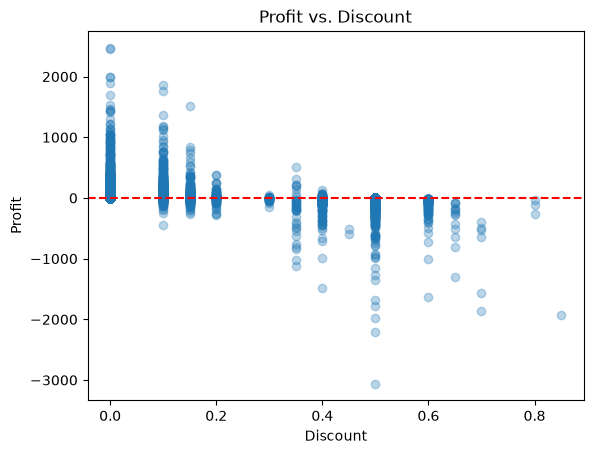

In [ ]:
print(df[['Discount','Profit']].corr())

import matplotlib.pyplot as plt
plt.scatter(df['Discount'], df['Profit'], alpha=0.3)
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.title('Profit vs. Discount')
plt.axhline(0, color='red', linestyle='--')
plt.show()

High Discount rates observed for items with negative profit margins which notes that cost is not covered at the discounted price which could be a business outcome and not a data error. Plotting the profit against discount shows this relationship

In [ ]:
mask, lower, upper = iqr_outliers(df['Profit'])

# highest-profit flagged rows
df[mask].sort_values('Profit', ascending=False)[['Product Name','Category','Sales','Profit','Quantity','Discount']].head(10)


,Product Name,Category,Sales,Profit,Quantity,Discount
868,"Hamilton Beach Stove, Silver",Office Supplies,6517,2476,12,0.00
1970,"Nokia Smart Phone, Full Size",Technology,5725,2461,9,0.00
4229,"Hoover Stove, Red",Office Supplies,3979,1990,7,0.00
2317,"Hoover Stove, Red",Office Supplies,3979,1990,7,0.00
3592,"KitchenAid Refrigerator, Black",Office Supplies,5274,1898,10,0.00
117,"SAFCO Executive Leather Armchair, Black",Furniture,4544,1868,11,0.10
711,"Cisco Smart Phone, Cordless",Technology,5277,1759,9,0.10
5499,"Brother Fax Machine, Laser",Technology,4141,1698,13,0.00
1419,"Chromcraft Computer Table, Adjustable Height",Furniture,3119,1528,7,0.00
1130,"Cisco Smart Phone, with Caller ID",Technology,4449,1518,8,0.15


In [ ]:
from itertools import combinations
import collections

edge_counts = collections.Counter()
for order_id, group in df.groupby('Order ID')['Product Name']:
    products = group.unique()
    for p1, p2 in combinations(sorted(products), 2):
        edge_counts[(p1, p2)] += 1

print("Number of product nodes:", df['Product Name'].nunique())
print("Number of co-purchase edges:", len(edge_counts))

import networkx as nx
G = nx.Graph()
for (p1, p2), w in edge_counts.items():
    G.add_edge(p1, p2, weight=w)

degrees = [d for _, d in G.degree()]
import pandas as pd
print(pd.Series(degrees).describe())
print("Isolated products (no co-purchase edge):", df['Product Name'].nunique() - G.number_of_nodes())
print("Connected components:", nx.number_connected_components(G))

Number of product nodes: 1810
Number of co-purchase edges: 7619
count    1718.000000
mean        8.869616
std         7.293849
min         1.000000
25%         3.250000
50%         7.000000
75%        12.000000
max        49.000000
dtype: float64
Isolated products (no co-purchase edge): 92
Connected components: 6


In [ ]:
same_category = sum(
    1 for (p1, p2) in edge_counts
    if product_features.loc[p1, 'category'] == product_features.loc[p2, 'category']
) / len(edge_counts)
print(f"Fraction of co-purchase edges within the same Category: {same_category:.2%}")

Fraction of co-purchase edges within the same Category: 49.18%


In [ ]:
comp_sizes = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
print(comp_sizes)
print(f"Largest component covers {comp_sizes[0]/G.number_of_nodes()*100:.1f}% of connected products")

[1706, 4, 2, 2, 2, 2]
Largest component covers 99.3% of connected products


The product co-purchase graph constructed from the EuroMart Stores dataset contains 1,810 product nodes connected by 7,619 co-purchase edges, where an edge links two products that appeared together in at least one customer order. Of these products, 1,718 (94.9%) participate in at least one co-purchase relationship, with the remaining 92 products (5.1%) purchased exclusively in isolation. Among connected products, the average degree is 8.87 (median 7), indicating that a typical product is linked to roughly seven to nine others, while a smaller number of high-degree "hub" products (maximum degree 49) are frequently co-purchased alongside a wide variety of items, consistent with common retail patterns where staple goods appear across many different order combinations. Critically, connectivity analysis reveals that 1,706 of the 1,718 connected products (99.3%) belong to a single giant connected component, with only five minor, mutually isolated clusters of two to four products remaining outside it. This near-total connectivity is a strong indicator of GNN suitability: because graph neural networks propagate information through message passing along edges, a graph dominated by one large connected component allows learned representations to draw on rich, multi-hop neighborhood context across almost the entire product catalog, rather than being fragmented into disconnected subgraphs that would each need to be modeled independently. Combined with the dataset's clean, unambiguous product identity (Product Name) and consistent category hierarchy, these structural properties indicate that the dataset provides sufficient graph density and connectivity to support meaningful GNN-based learning, rather than reducing to a sparse or disconnected network where graph-based methods would offer little advantage over standard tabular models.

To prepare for GNN, these are the prerequisites 
1. Clean unique node identity where it is a identifier of real world entity, verified since Product Name is 1810 products with no near duplicate and consistent hierarchy.
2. clean underlying data with bad values eg. negative prices, discounts over 100%
3. Enough entities and enough interactions per entity since we need nodes and nodes need to be connected to allow message passing, the nodes should not be isolated singletons. This is checked with cardinality and degree distribution  with 7 co-purchase edges per product, and only 5 % fully isolated.
4. Graph connectivity: nodes are connected directly or indirectly from each other so that GNN will work.
5. Trustworthy node and edge features :the nodes should be described easily
6. No outliers

Saving the cleaned dataset to local 

In [ ]:
df.to_csv("/Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project/Data/EuroMart_Stores_cleaned.csv", index=False)

# Part 2: Dataset and graph-feasibility audit

Data-level audit of the cleaned EuroMart data before any modelling: column mapping, customer-item graph structure, temporal coverage, Jaccard similarity vs null, sub-category lift, and history persistence.

## Setup

Imports and seed only (no PyTorch / PyG needed for EDA).

In [ ]:
import os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed()

## Phase 1 — Dataset audit

**What:** list the project's `Data/` folder and the notebook's working directory.

**Why:** find the raw file before loading anything. Earlier cells wrote a cleaned CSV, so there may be both a raw xlsx and a cleaned csv. I'll confirm which one to use before loading.

In [ ]:
print('cwd:', os.getcwd())
!ls -la .
print('\n--- Data/ ---')
!ls -la Data

cwd: /Users/engyixuan/Documents/Y4S1/SC4020 Data Mining/Project
total 11704
drwxr-xr-x  9 engyixuan  staff      288 Oct 12 09:53 .
drwxr-xr-x  6 engyixuan  staff      192 Sep 11 14:20 ..
-rw-r--r--@ 1 engyixuan  staff     6148 Oct 12 09:50 .DS_Store
drwxr-xr-x  4 engyixuan  staff      128 Oct 12 09:42 .ipynb_checkpoints
drwxr-xr-x  5 engyixuan  staff      160 Sep 11 17:25 Data
-rw-r--r--@ 1 engyixuan  staff  2991471 Oct 12 09:53 DataCleaningData2.ipynb
drwxr-xr-x  2 engyixuan  staff       64 Oct 12 09:50 EuroMart Split
-rw-r--r--@ 1 engyixuan  staff  2987981 Oct  2 00:08 GCN_with_GAT_Yi Xuan.ipynb
-rw-r--r--  1 engyixuan  staff        0 Oct 12 09:55 gnn_faulthandler.log

--- Data/ ---
total 20104
drwxr-xr-x  5 engyixuan  staff      160 Sep 11 17:25 .
drwxr-xr-x  9 engyixuan  staff      288 Oct 12 09:53 ..
-rw-rw-r--@ 1 engyixuan  staff  1157873 Sep 11 16:02 Capstone1C_EuroMart Stores-1.xlsx
-rw-r--r--@ 1 engyixuan  staff  1397257 Oct 12 09:54 EuroMart_Stores_cleaned.csv
-rw-rw-r--@ 1 e

**Observation.** `Data/` holds three candidates: the raw `Capstone1C_EuroMart Stores-1.xlsx`, the teammate-cleaned `EuroMart_Stores_cleaned.csv`, and a separate `online_sales_dataset.csv` (7 MB). I'll peek at the header lines and xlsx sheet names only (no full load) so the user can confirm which file to use.

In [ ]:
import openpyxl
wb = openpyxl.load_workbook('Data/Capstone1C_EuroMart Stores-1.xlsx', read_only=True)
print('xlsx sheets:', wb.sheetnames)
print('\n--- EuroMart_Stores_cleaned.csv ---')
!head -n 3 Data/EuroMart_Stores_cleaned.csv; wc -l Data/EuroMart_Stores_cleaned.csv
print('\n--- online_sales_dataset.csv ---')
!head -n 3 Data/online_sales_dataset.csv; wc -l Data/online_sales_dataset.csv

xlsx sheets: ['Sheet1', 'Order Data']

--- EuroMart_Stores_cleaned.csv ---
Order ID,Order Date,Customer Name,Country,State,City,Region,Segment,Ship Mode,Category,Sub-Category,Product Name,Discount,Sales,Profit,Quantity,Feedback?,order_prefix
BN-2011-7407039,2011-01-01,Ruby Patel,Sweden,Stockholm,Stockholm,North,Home Office,Economy Plus,Office Supplies,Paper,"Enermax Note Cards, Premium",0.5,45,-26,3,False,BN
AZ-2011-9050313,2011-01-03,Summer Hayward,United Kingdom,England,Southport,North,Consumer,Economy,Furniture,Bookcases,"Dania Corner Shelving, Traditional",0.0,854,290,7,True,AZ
    8046 Data/EuroMart_Stores_cleaned.csv

--- online_sales_dataset.csv ---
InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Discount,PaymentMethod,ShippingCost,Category,SalesChannel,ReturnStatus,ShipmentProvider,WarehouseLocation,OrderPriority
221958,SKU_1964,White Mug,38,2020-01-01 00:00,1.71,37039.0,Australia,0.47,Bank Transfer,10.79,Apparel,In-store,Not Returned,UPS,Londo

**Decision (confirmed by user):** use `Data/EuroMart_Stores_cleaned.csv`, the output of the cleaning section above. `online_sales_dataset.csv` is not used anywhere in this notebook and is ignored.

**What:** load the CSV into a new frame `raw`, parse `Order Date`, and print shape, dtypes and head.

**Why:** a basic structural check. I keep `raw` untouched so every later drop can be logged against it.

In [ ]:
DATA_PATH = 'Data/EuroMart_Stores_cleaned.csv'
raw = pd.read_csv(DATA_PATH, parse_dates=['Order Date'])
print('shape:', raw.shape)
print()
print(raw.dtypes.to_string())
pd.set_option('display.width', 200, 'display.max_columns', 30)
raw.head()

shape: (8045, 18)

Order ID                    str
Order Date       datetime64[us]
Customer Name               str
Country                     str
State                       str
City                        str
Region                      str
Segment                     str
Ship Mode                   str
Category                    str
Sub-Category                str
Product Name                str
Discount                float64
Sales                     int64
Profit                    int64
Quantity                  int64
Feedback?                  bool
order_prefix                str


,Order ID,Order Date,Customer Name,Country,State,City,Region,Segment,Ship Mode,Category,Sub-Category,Product Name,Discount,Sales,Profit,Quantity,Feedback?,order_prefix
0,BN-2011-7407039,2011-01-01,Ruby Patel,Sweden,Stockholm,Stockholm,North,Home Office,Economy Plus,Office Supplies,Paper,"Enermax Note Cards, Premium",0.5,45,-26,3,False,BN
1,AZ-2011-9050313,2011-01-03,Summer Hayward,United Kingdom,England,Southport,North,Consumer,Economy,Furniture,Bookcases,"Dania Corner Shelving, Traditional",0.0,854,290,7,True,AZ
2,AZ-2011-6674300,2011-01-04,Devin Huddleston,France,Auvergne-Rhône-Alpes,Valence,Central,Consumer,Economy,Office Supplies,Art,"Binney & Smith Sketch Pad, Easy-Erase",0.0,140,21,3,True,AZ
3,BN-2011-2819714,2011-01-04,Mary Parker,United Kingdom,England,Birmingham,North,Corporate,Economy,Office Supplies,Art,"Boston Markers, Easy-Erase",0.5,27,-22,2,True,BN
4,BN-2011-2819714,2011-01-04,Mary Parker,United Kingdom,England,Birmingham,North,Corporate,Economy,Office Supplies,Storage,"Eldon Folders, Single Width",0.5,17,-1,2,True,BN


**Insight (load).** 8,045 rows × 18 columns, matching the 8,047 raw rows minus the 2 exact duplicates removed earlier, plus the derived `order_prefix`. Dtypes are sensible: `Order Date` parsed as datetime, money and quantity as int, `Feedback?` as bool. **There is no customer ID column, only `Customer Name`**, so I need to check whether a name is a reliable key.

**What next:** missing values, duplicates at several grains (full row, same order+product line), numeric ranges and the cardinality of every column.

In [ ]:
print('Missing values per column:'); print(raw.isna().sum()[raw.isna().sum()>0].to_string() or '  none')
print('Empty / whitespace-only strings:', int((raw.select_dtypes('object').apply(lambda s: s.astype(str).str.strip()=='')).sum().sum()) if len(raw.select_dtypes('object').columns) else int(raw.astype(str).apply(lambda s: s.str.strip()=='').sum().sum()))
print()
print('Exact duplicate rows            :', raw.duplicated().sum())
print('Dup (Order ID, Product Name)    :', raw.duplicated(['Order ID','Product Name']).sum())
print('Orders with >1 customer name    :', (raw.groupby('Order ID')['Customer Name'].nunique()>1).sum())
print('Orders with >1 date             :', (raw.groupby('Order ID')['Order Date'].nunique()>1).sum())
print()
print('Date range:', raw['Order Date'].min().date(), '->', raw['Order Date'].max().date())
print()
print(raw[['Discount','Sales','Profit','Quantity']].describe().T.to_string())
print()
print('Cardinality:'); print(raw.nunique().to_string())

Missing values per column:
Series([], )
Empty / whitespace-only strings: 0

Exact duplicate rows            : 0
Dup (Order ID, Product Name)    : 3
Orders with >1 customer name    : 0
Orders with >1 date             : 0

Date range: 2011-01-01 -> 2014-12-31

           count        mean         std     min   25%    50%    75%      max
Discount  8045.0    0.110075    0.181787     0.0   0.0    0.0    0.1     0.85
Sales     8045.0  291.903170  485.258616     3.0  48.0  117.0  313.0  6517.00
Profit    8045.0   35.202237  178.147747 -3060.0   1.0   14.0   47.0  2476.00
Quantity  8045.0    3.772281    2.203610     1.0   2.0    3.0    5.0    14.00

Cardinality:
Order ID         4117
Order Date       1214
Customer Name     792
Country            15
State             127
City              999
Region              3
Segment             3
Ship Mode           4
Category            3
Sub-Category       17
Product Name     1810
Discount           14
Sales            1248
Profit            845
Quantit

/var/folders/x6/13qvtl1n1ksgn9xvx06mdqj00000gn/T/ipykernel_33565/625839635.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print('Empty / whitespace-only strings:', int((raw.select_dtypes('object').apply(lambda s: s.astype(str).str.strip()=='')).sum().sum()) if len(raw.select_dtypes('object').columns) else int(raw.astype(str).apply(lambda s: s.str.strip()=='').sum().sum()))
/var/folders/x6/13qvtl1n1ksgn9xvx06mdqj00000gn/T/ipykernel_33565/625839635.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specifi

**Insight (integrity).** *Expected* few problems because this file is already cleaned. *Observed:* no missing values, no exact duplicates, and every Order ID has exactly one customer and one date, so order headers are consistent. Dates span **2011-01-01 → 2014-12-31 (48 months)**, so a temporal setup is possible. Numeric ranges are plausible: discount 0–0.85, quantity 1–14, negative profit only when discounted (seen earlier).

**Two red flags for the task:**
1. **`Category` has only 3 values** (Furniture, Office Supplies, Technology). A 3-class customer–category graph is almost certainly near-complete, so `Sub-Category` (17) or `Product Name` (1,810) is the real item level. Phase 2 will test this.
2. **792 customers, 4,117 orders over 48 months**, about 5 orders per customer in 4 years. Monthly t→t+1 targets will be very sparse. Coarser periods (quarters) may be needed. Also checked in Phase 2.

**Minor:** 3 rows repeat an (Order ID, Product Name) pair. *Next:* inspect those rows and test whether `Customer Name` is a safe customer key (one name in several countries or segments could be two different people).

In [ ]:
# (a) the 3 repeated order-product lines
dup_mask = raw.duplicated(['Order ID','Product Name'], keep=False)
display(raw.loc[dup_mask, ['Order ID','Order Date','Customer Name','Product Name','Discount','Sales','Profit','Quantity']].sort_values('Order ID'))

# (b) is Customer Name a stable key?
g = raw.groupby('Customer Name')
key_check = pd.DataFrame({
    'n_countries': g['Country'].nunique(), 'n_cities': g['City'].nunique(),
    'n_regions': g['Region'].nunique(),   'n_segments': g['Segment'].nunique(),
    'n_orders': g['Order ID'].nunique()})
for c in ['n_countries','n_cities','n_regions','n_segments']:
    print(f'{c:12s}: customers with >1 value = {(key_check[c]>1).sum():4d} / {len(key_check)}  (max {key_check[c].max()})')

# (c) label hygiene: leading/trailing spaces or case variants in categorical columns
cat_cols = ['Customer Name','Country','State','City','Region','Segment','Ship Mode','Category','Sub-Category','Product Name']
for c in cat_cols:
    s = raw[c].astype(str)
    n_strip = (s != s.str.strip()).sum()
    n_case  = s.nunique() - s.str.strip().str.lower().nunique()
    if n_strip or n_case: print(f'{c}: {n_strip} untrimmed, {n_case} case-variant collisions')
print('label hygiene check done')
print(sorted(raw['Category'].unique())); print(sorted(raw['Sub-Category'].unique()))

,Order ID,Order Date,Customer Name,Product Name,Discount,Sales,Profit,Quantity
3215,AZ-2012-1622139,2012-12-17,Joel McKean,"Stanley Canvas, Water Color",0.1,332,125,7
3216,AZ-2012-1622139,2012-12-17,Joel McKean,"Stanley Canvas, Water Color",0.1,379,143,8
1646,AZ-2012-3398854,2012-03-03,Phoebe Moore,"Fellowes Trays, Industrial",0.0,116,28,2
1647,AZ-2012-3398854,2012-03-03,Phoebe Moore,"Fellowes Trays, Industrial",0.0,174,42,3
7801,BN-2014-6653003,2014-12-09,Libby Allan,"Office Star Bag Chairs, Adjustable",0.5,58,-42,2
7802,BN-2014-6653003,2014-12-09,Libby Allan,"Office Star Bag Chairs, Adjustable",0.5,145,-104,5


n_countries : customers with >1 value =  753 / 792  (max 8)
n_cities    : customers with >1 value =  761 / 792  (max 13)
n_regions   : customers with >1 value =  698 / 792  (max 3)
n_segments  : customers with >1 value =    0 / 792  (max 1)
label hygiene check done
['Furniture', 'Office Supplies', 'Technology']
['Accessories', 'Appliances', 'Art', 'Binders', 'Bookcases', 'Chairs', 'Copiers', 'Envelopes', 'Fasteners', 'Furnishings', 'Labels', 'Machines', 'Paper', 'Phones', 'Storage', 'Supplies', 'Tables']


**Insight (keys and labels).**
- **Repeated order lines:** each of the 3 pairs is the same product in the same order with different quantity and sales, so these are *split lines*, not duplicates. Dropping one would lose real volume. **Action: merge** each pair into one line (sum Sales, Profit, Quantity; keep Discount, which is equal within each pair).
- **Customer key:** 753 of 792 customers ship to more than one country (up to 8) and 698 to more than one region, yet **every customer has exactly one Segment**. So `Customer Name` is a consistent identity, and **Country/State/City/Region are per-order ship-to attributes, not customer demographics**. The only static customer attribute is `Segment` (3 levels). Location can still be used as a history-derived feature (e.g. share of a customer's past orders per region), computed only from data up to *t*.
- **Labels:** no untrimmed strings or case variants in any categorical column. Nothing to standardise.

*Next:* build the clean interaction table `df` with integer IDs and a drop/merge log.

**What:** create the GNN-ready interaction table `df`: merge split lines, drop rows with invalid IDs or non-positive quantity/sales (expected: none), add integer IDs for customers, categories, sub-categories and products, and add a `month` period column. Every change is recorded in `clean_log`.

**Why:** later phases need contiguous integer node indices and a period key. The log makes the row count fully auditable.

In [ ]:
clean_log = []
def log(step, before, after, why):
    clean_log.append({'step': step, 'rows_before': before, 'rows_after': after, 'rows_removed': before-after, 'reason': why})

df = raw.copy()

# 1) invalid IDs / empty keys
n0 = len(df)
key_cols = ['Order ID','Customer Name','Product Name','Category','Sub-Category','Order Date']
df = df.dropna(subset=key_cols)
df = df[~df[key_cols[:-1]].apply(lambda s: s.astype(str).str.strip().eq('')).any(axis=1)]
log('drop invalid/empty IDs', n0, len(df), 'null or blank key column')

# 2) non-positive quantity or sales (returns / errors)
n0 = len(df)
df = df[(df['Quantity'] > 0) & (df['Sales'] > 0)]
log('drop non-positive qty/sales', n0, len(df), 'Quantity<=0 or Sales<=0')

# 3) merge split order lines (same Order ID + Product Name)
n0 = len(df)
pair_keys = ['Order ID','Product Name']
dup_lines = df[df.duplicated(pair_keys, keep=False)]
other = [c for c in df.columns if c not in pair_keys + ['Sales','Profit','Quantity']]
diff_cols = [c for c in other if (dup_lines.groupby(pair_keys)[c].nunique() > 1).any()]
print('columns that differ within split-line pairs:', diff_cols)
display(dup_lines[pair_keys + diff_cols]) if diff_cols else None
agg = {c: 'first' for c in other}; agg.update({'Sales':'sum', 'Profit':'sum', 'Quantity':'sum'})
df = df.groupby(pair_keys, as_index=False, sort=False).agg(agg)[raw.columns]
log('merge split order lines', n0, len(df), 'same order+product on 2 lines -> summed Sales/Profit/Quantity, first value for other cols')
assert not df.duplicated(['Order ID','Product Name']).any()

# 4) integer IDs + period
df = df.rename(columns={'Feedback?':'Feedback'}).sort_values(['Order Date','Order ID']).reset_index(drop=True)
for col, new in [('Customer Name','cust_id'), ('Category','cat_id'), ('Sub-Category','subcat_id'), ('Product Name','prod_id')]:
    df[new] = df[col].astype('category').cat.codes.astype(int)
df['month'] = df['Order Date'].dt.to_period('M')

clean_log_df = pd.DataFrame(clean_log)
display(clean_log_df)
print(f'raw rows {len(raw)} -> clean rows {len(df)}  (net change {len(df)-len(raw)})')
print('customers', df.cust_id.nunique(), '| categories', df.cat_id.nunique(), '| sub-categories', df.subcat_id.nunique(), '| products', df.prod_id.nunique(), '| months', df.month.nunique())
print('Sales/Profit/Quantity totals preserved:', np.allclose(raw[['Sales','Profit','Quantity']].sum().values, df[['Sales','Profit','Quantity']].sum().values))

columns that differ within split-line pairs: ['Feedback?']


,Order ID,Product Name,Feedback?
1646,AZ-2012-3398854,"Fellowes Trays, Industrial",False
1647,AZ-2012-3398854,"Fellowes Trays, Industrial",True
3215,AZ-2012-1622139,"Stanley Canvas, Water Color",False
3216,AZ-2012-1622139,"Stanley Canvas, Water Color",False
7801,BN-2014-6653003,"Office Star Bag Chairs, Adjustable",True
7802,BN-2014-6653003,"Office Star Bag Chairs, Adjustable",False


,step,rows_before,rows_after,rows_removed,reason
0,drop invalid/empty IDs,8045,8045,0,null or blank key column
1,drop non-positive qty/sales,8045,8045,0,Quantity<=0 or Sales<=0
2,merge split order lines,8045,8042,3,same order+product on 2 lines -> summed Sales/...


raw rows 8045 -> clean rows 8042  (net change -3)
customers 792 | categories 3 | sub-categories 17 | products 1810 | months 48
Sales/Profit/Quantity totals preserved: True


**Insight (cleaning).** First attempt failed my own assert: grouping by *all* non-numeric columns kept the pairs apart because `Feedback?` differs inside 2 of the 3 pairs. Fixed by grouping on (Order ID, Product Name) only, summing the numeric columns and taking the first value elsewhere. Feedback is a line-level survey flag and is not used as a model input, so this choice is harmless.

**Result:** 8,045 → **8,042 rows** (3 merges, 0 drops). Sales, profit and quantity totals are preserved exactly. 792 customers, 3 categories, 17 sub-categories, 1,810 products, 48 months.

*Next:* outlier inspection on Sales and Quantity, and activity per customer. Inspect only: large B2B-style orders are real behaviour, and an interaction graph does not need them removed.

**Save the cleaned, GNN-ready table.** This is the file GCN_DS1_EuroMart loads: split order lines merged, `Feedback` column renamed, and integer IDs (`cust_id`, `cat_id`, `subcat_id`, `prod_id`) added. Saved as a new file so `EuroMart_Stores_cleaned.csv` stays unchanged.

In [ ]:
out = df.copy()
out['month'] = out['Order Date'].dt.to_period('M').astype(str)
out['quarter'] = out['Order Date'].dt.to_period('Q').astype(str)
out.to_csv('Data/EuroMart_DS1_cleaned.csv', index=False)
print('saved', out.shape, '->', 'Data/EuroMart_DS1_cleaned.csv')

Sales   :  446 rows (5.5%) outside 3*IQR [-747, 1108]
Quantity:    1 rows (0.0%) outside 3*IQR [-7, 14]
Profit  :  845 rows (10.5%) outside 3*IQR [-137, 185]

Per-customer activity:
                                 mean                  50%                  min                  max
n_orders                     5.198232                  5.0                  1.0                 13.0
n_lines                      10.15404                  9.0                  1.0                 32.0
n_months                     4.893939                  5.0                  1.0                 12.0
n_subcats                    6.799242                  7.0                  1.0                 15.0
first             2012-01-01 19:00:00  2011-10-15 12:00:00  2011-01-01 00:00:00  2014-12-29 00:00:00
last       2014-06-16 18:49:05.454545  2014-09-02 12:00:00  2011-02-18 00:00:00  2014-12-31 00:00:00


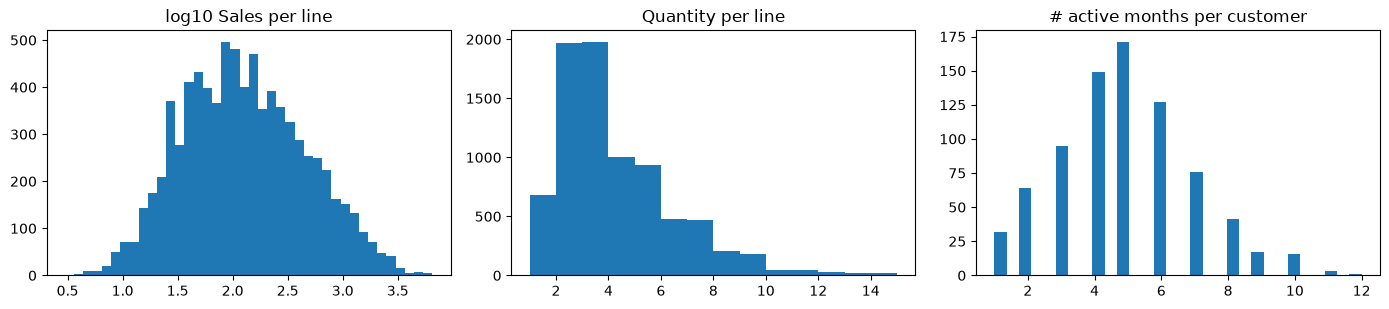

In [ ]:
def iqr_flags(s, k=3.0):
    q1, q3 = s.quantile([.25, .75]); lo, hi = q1 - k*(q3-q1), q3 + k*(q3-q1)
    return (s < lo) | (s > hi), lo, hi
for col in ['Sales','Quantity','Profit']:
    m, lo, hi = iqr_flags(df[col])
    print(f'{col:8s}: {m.sum():4d} rows ({m.mean():.1%}) outside 3*IQR [{lo:.0f}, {hi:.0f}]')

cust = df.groupby('cust_id').agg(n_orders=('Order ID','nunique'), n_lines=('Order ID','size'),
                                 n_months=('month','nunique'), n_subcats=('subcat_id','nunique'),
                                 first=('Order Date','min'), last=('Order Date','max'))
print('\nPer-customer activity:'); print(cust.describe().T[['mean','50%','min','max']].round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].hist(np.log10(df['Sales']), bins=40); ax[0].set_title('log10 Sales per line')
ax[1].hist(df['Quantity'], bins=14); ax[1].set_title('Quantity per line')
ax[2].hist(cust['n_months'], bins=30); ax[2].set_title('# active months per customer')
plt.tight_layout(); plt.show()

**Insight (outliers and activity).** Sales is right-skewed (5.5% of lines exceed 3×IQR, max 6,517) but log-normal-looking with no impossible values. Profit outliers are the known discount-driven losses. Only 1 quantity outlier: the merged 7+8 = 15 canvas line. **Decision: keep all rows.** These are real purchases, and for edge weights I'll use `log(1+count)` / `log1p(spend)`, which already dampens them.

The important number is **activity: the median customer is active in only 5 of 48 months** (max 12). So in any month only about 10% of customers buy anything, and most customer–month targets `Y_{t+1}` will be empty. This strongly shapes Phase 2/3: either restrict evaluation to customers who buy in t+1 (standard next-basket protocol) or use quarterly periods. I'll quantify both in Phase 2.

### Phase 1 summary — column mapping

| Role | Column(s) | Notes |
|---|---|---|
| **Customer ID** | `Customer Name` → `cust_id` | no numeric ID exists; name is consistent (1 segment per customer); 792 customers |
| **Item (category level)** | `Category` → `cat_id` | **only 3 values**, almost certainly too coarse |
| **Item (mid level)** | `Sub-Category` → `subcat_id` | 17 values, the likely "category" for this task |
| **Item (product level)** | `Product Name` → `prod_id` | 1,810 products; no SKU code |
| **Interaction / event** | each row = purchase line | **purchases only**: no view/cart/return events |
| **Timestamp** | `Order Date` → `month` | daily, 2011-01 → 2014-12, 48 months |
| **Customer attributes** | `Segment` | Consumer / Corporate / Home Office; the only static attribute |
| **Order attributes** | `Country`, `State`, `City`, `Region`, `Ship Mode`, `order_prefix` | vary *per order* for the same customer, so ship-to info, not demographics |
| **Transaction attributes** | `Sales`, `Quantity`, `Discount`, `Profit`, `Feedback` | used for edge summaries (spend, quantity); no ratings |

**Rows:** 8,045 → 8,042 (3 split lines merged, 0 dropped).

## Phase 2 — Graph feasibility audit

**What:** build the customer–item bipartite graph at three item granularities (Category 3, Sub-Category 17, Product 1,810). Repeat purchases are aggregated into one weighted edge. For each graph I compute size, density, degree statistics, connected components, degree-1 share, 5-core/10-core survival and repeat rate.

**Why:** these are the decision gates. A near-complete graph (density → 1) gives message passing nothing to discriminate, and a graph that collapses under k-core filtering is too sparse to learn from. The audit uses the full 4-year graph because it is descriptive only; no model sees it.

In [ ]:
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

LEVELS = {'category': 'cat_id', 'subcategory': 'subcat_id', 'product': 'prod_id'}

def bipartite_edges(d, item_col):
    """one edge per (customer, item); weight = #purchase lines, #orders, spend"""
    return d.groupby(['cust_id', item_col]).agg(n_lines=('Order ID','size'), n_orders=('Order ID','nunique'),
                                                 spend=('Sales','sum'), qty=('Quantity','sum')).reset_index()

def kcore_bipartite(e, item_col, k):
    e = e[['cust_id', item_col]]
    while True:
        du = e.groupby('cust_id').size(); di = e.groupby(item_col).size()
        keep = e['cust_id'].map(du).ge(k) & e[item_col].map(di).ge(k)
        if keep.all(): return e
        e = e[keep]

def graph_stats(d, item_col):
    e = bipartite_edges(d, item_col)
    U, I, E = d['cust_id'].nunique(), d[item_col].nunique(), len(e)
    du, di = e.groupby('cust_id').size(), e.groupby(item_col).size()
    # connected components on the bipartite graph (items offset by U)
    uid = e['cust_id'].astype('category').cat.codes.values.astype(np.int64); iid = e[item_col].astype('category').cat.codes.values.astype(np.int64) + U
    A = sp.coo_matrix((np.ones(E), (uid, iid)), shape=(U+I, U+I))
    ncomp, lab = connected_components(A, directed=False)
    out = {'|U|': U, '|I|': I, '|E|': E, 'density': E/(U*I),
           'cust deg mean': du.mean(), 'cust deg median': du.median(),
           'item deg mean': di.mean(), 'item deg median': di.median(),
           'components': ncomp, 'largest comp %': np.bincount(lab).max()/(U+I),
           '% cust deg=1': (du==1).mean(), '% items deg=1': (di==1).mean(),
           'repeat-edge rate': (e['n_orders']>1).mean(),       # edges bought in >1 order
           'repeat-purchase share': 1 - E/e['n_orders'].sum()} # share of (cust,item,order) events that are repeats
    for k in (5, 10):
        kc = kcore_bipartite(e, item_col, k)
        out[f'{k}-core cust %'] = kc['cust_id'].nunique()/U
        out[f'{k}-core item %'] = kc[item_col].nunique()/I
    return out, e

stats, edges = {}, {}
for name, col in LEVELS.items():
    stats[name], edges[name] = graph_stats(df, col)
stats_df = pd.DataFrame(stats)
fmt = stats_df.copy().astype(object)
for r in stats_df.index:
    fmt.loc[r] = [f'{v:.1%}' if ('%' in r or 'rate' in r or 'share' in r or r=='density') else (f'{v:,.0f}' if float(v).is_integer() else f'{v:,.2f}') for v in stats_df.loc[r]]
fmt

,category,subcategory,product
|U|,792,792,792
|I|,3,17,"1,810"
|E|,"2,025","5,385","8,010"
density,85.2%,40.0%,0.6%
cust deg mean,2.56,6.80,10.11
cust deg median,3,7,9
item deg mean,675,316.76,4.43
item deg median,643,288,4
components,1,1,1
largest comp %,100.0%,100.0%,100.0%


**Insight (structure).** First run failed with an int8 overflow: pandas category codes are int8 and adding U = 792 overflowed. Fixed by casting to int64.

| | Category (3) | Sub-category (17) | Product (1,810) |
|---|---|---|---|
| density | **85%**, near-complete | **40%** | **0.6%** |
| repeat-edge rate | 70% | 29% | **0.4%** |
| 10-core survival (cust) | 0% (only 3 items) | 16% | **0%** |

- **Category level is degenerate:** 85% of all possible edges exist and the median customer already touches all 3 categories. A GNN cannot learn anything that popularity does not already give.
- **Product level is the opposite extreme:** density 0.6%, median 4 buyers per product, 13.5% of products bought by one customer only, and **only 0.4% of customer–product edges ever repeat**. Next-period product prediction would almost entirely be *new-item discovery* from ~10 historical edges per customer, and the 10-core is empty. That is a much harder and noisier task.
- **Sub-category is the workable middle:** one connected component, 98% of customers have degree ≥ 2, all 17 items survive the 5-core, 81% of customers survive the 5-core, and there is a meaningful mix of repeat (29%) and new edges.

*Expected:* category too dense, as suspected in Phase 1. *Surprise:* how little product repetition there is. *Next:* degree distributions on a log scale to see the shape behind these means.

**What:** customer and item degree histograms per level, with log-scaled count axes.

**Why:** GCN normalises messages by 1/√(d_i·d_j), so skewed degrees mean hub items get heavily down-weighted. The shape of the distribution tells us how much that matters, and whether there is a long tail of low-degree nodes where GAT's learned weights might help.

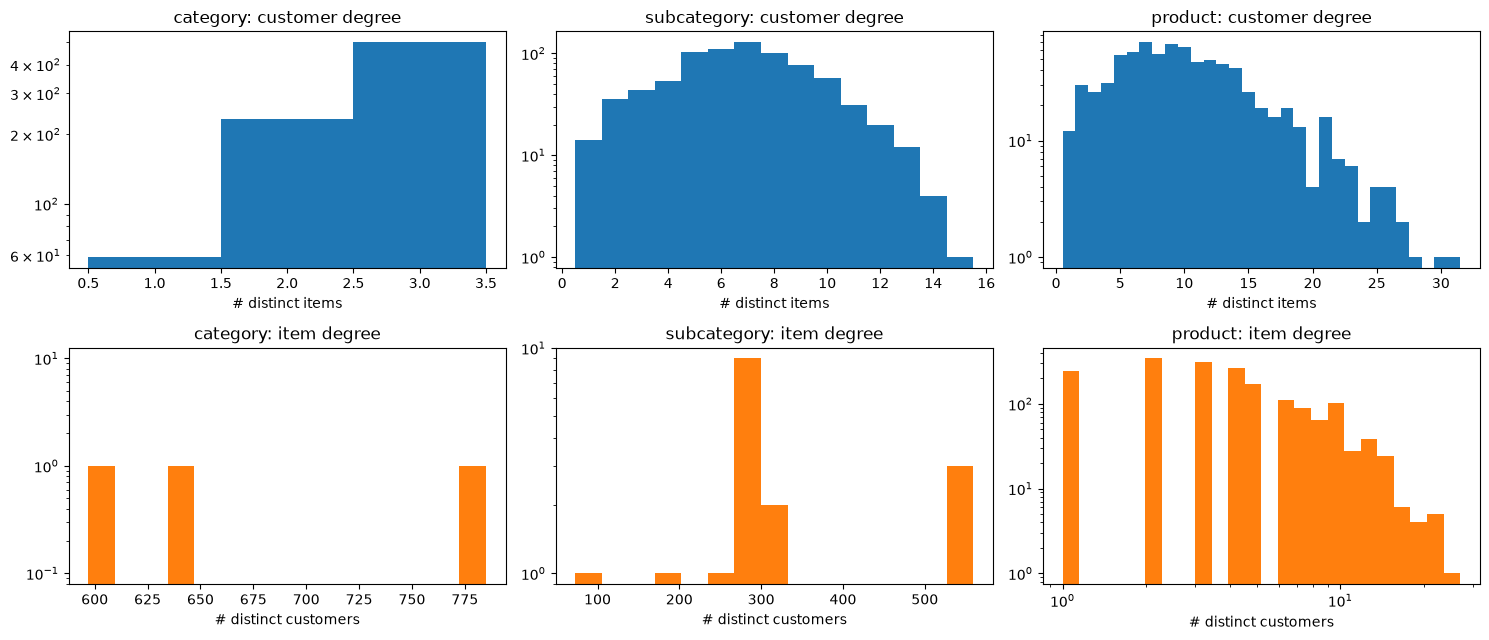

sub-category item degrees (customers per sub-category):
subcat_id
Art            559
Storage        556
Binders        542
Phones         330
Chairs         300
Furnishings    297
Bookcases      293
Copiers        290
Fasteners      288
Paper          285
Supplies       281
Labels         281
Accessories    275
Machines       269
Envelopes      267
Appliances     199
Tables          73


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for j, (name, col) in enumerate(LEVELS.items()):
    e = edges[name]
    du, di = e.groupby('cust_id').size(), e.groupby(col).size()
    axes[0, j].hist(du, bins=np.arange(1, du.max()+2)-0.5, color='tab:blue')
    axes[0, j].set_yscale('log'); axes[0, j].set_title(f'{name}: customer degree'); axes[0, j].set_xlabel('# distinct items')
    bins = np.logspace(0, np.log10(di.max()+1), 25) if name=='product' else 15
    axes[1, j].hist(di, bins=bins, color='tab:orange')
    axes[1, j].set_yscale('log'); axes[1, j].set_title(f'{name}: item degree'); axes[1, j].set_xlabel('# distinct customers')
    if name=='product': axes[1, j].set_xscale('log')
plt.tight_layout(); plt.show()
print('sub-category item degrees (customers per sub-category):')
print(edges['subcategory'].groupby('subcat_id').size().rename(index=dict(zip(df.subcat_id, df['Sub-Category']))).sort_values(ascending=False).to_string())

**Insight (degrees).** Customer degree at sub-category level is close to bell-shaped (mode about 7 of 17) with no heavy tail, so customers are fairly homogeneous in breadth. Item degrees fall into **three tiers**: Art, Storage and Binders (~550 customers each, about 70% of all customers), a flat middle block of ~270–330, and two weak items, Appliances (199) and Tables (73). Under GCN normalisation the three hub items will be down-weighted the most. Product level shows the expected long tail: a log-log decreasing item-degree histogram with many degree-1 to 3 products.

*Next:* the time dimension. How many months are usable, how many customers are active per period, and how fast new customers arrive, for both monthly and quarterly periods.

**What:** for monthly and quarterly periods: active customers per period, new (first-seen) customers per period, and the share of active customers that were already seen before.

**Why:** the task predicts t+1 from history up to t. A period is only *usable* as a target if it has enough active customers with prior history. Customers first seen in t+1 are cold-start and cannot be scored by a transductive GNN.

MONTH: 48 periods | active/period mean 81 (min 34, max 170) | active as % of 792: 10.2% | mean returning share (after 1st yr) 88.6%
QUARTER: 16 periods | active/period mean 219 (min 113, max 328) | active as % of 792: 27.7% | mean returning share (after 1st yr) 87.6%
month when 50% / 90% / 99% of customers have been seen: 2011-10 / 2013-02 / 2014-06


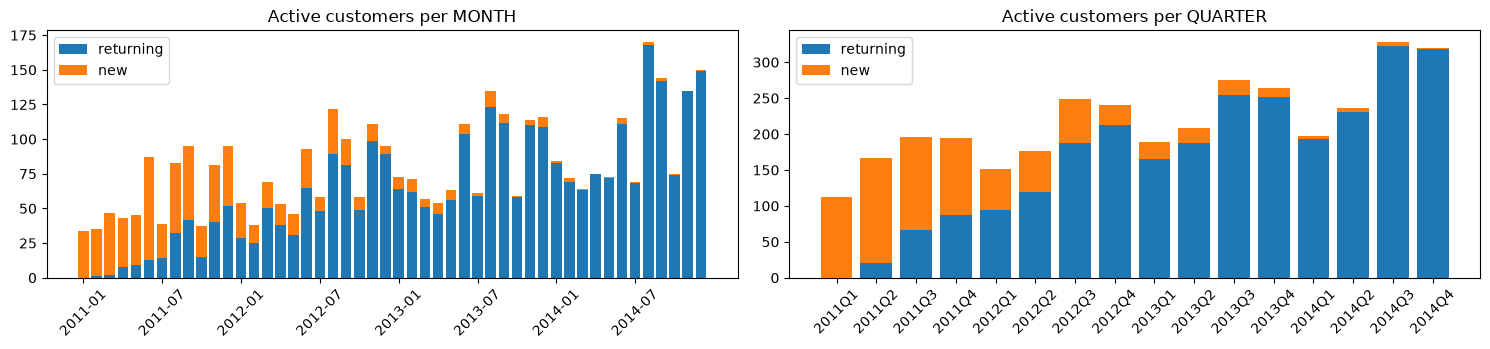

In [ ]:
df['quarter'] = df['Order Date'].dt.to_period('Q')
first_seen = df.groupby('cust_id')['Order Date'].min()

def temporal_profile(period_col):
    rows = []
    seen = set()
    for p, g in df.groupby(period_col, sort=True):
        act = set(g['cust_id'])
        new = act - seen
        rows.append({'period': str(p), 'active': len(act), 'new': len(new), 'returning': len(act & seen),
                     'cum_seen': len(seen | act)})
        seen |= act
    t = pd.DataFrame(rows)
    t['pct_returning'] = t['returning'] / t['active']
    return t

tm, tq = temporal_profile('month'), temporal_profile('quarter')
for name, t in [('MONTH', tm), ('QUARTER', tq)]:
    print(f'{name}: {len(t)} periods | active/period mean {t.active.mean():.0f} (min {t.active.min()}, max {t.active.max()}) '
          f'| active as % of 792: {t.active.mean()/792:.1%} | mean returning share (after 1st yr) {t.pct_returning.iloc[len(t)//4:].mean():.1%}')
frac_seen = tm.set_index('period')['cum_seen']/792
print('month when 50% / 90% / 99% of customers have been seen:',
      frac_seen[frac_seen>=.5].index[0], '/', frac_seen[frac_seen>=.9].index[0], '/', frac_seen[frac_seen>=.99].index[0])

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
ax[0].bar(range(len(tm)), tm['returning'], label='returning'); ax[0].bar(range(len(tm)), tm['new'], bottom=tm['returning'], label='new')
ax[0].set_xticks(range(0, len(tm), 6)); ax[0].set_xticklabels(tm.period[::6], rotation=45); ax[0].set_title('Active customers per MONTH'); ax[0].legend()
ax[1].bar(range(len(tq)), tq['returning'], label='returning'); ax[1].bar(range(len(tq)), tq['new'], bottom=tq['returning'], label='new')
ax[1].set_xticks(range(len(tq))); ax[1].set_xticklabels(tq.period, rotation=45); ax[1].set_title('Active customers per QUARTER'); ax[1].legend()
plt.tight_layout(); plt.show()

**Insight (time).** All 48 months have data, but **only about 81 customers (10%) buy in a typical month** (34–170). Per quarter it is ~219 (28%). Volume grows over time with clear year-end peaks: Sep/Nov/Dec and Q4. New customers arrive quickly early on (50% seen by Oct 2011, 90% by Feb 2013, 99% by Jun 2014), so from 2013 onwards ~90% of active customers are returning. Cold-start in the val/test window (2014) will therefore be small.

*Implication for the split:* with monthly periods each target month has only ~80–150 customers to evaluate. Quarterly targets give 2–3× more evaluation customers per period and fewer empty rows. *Next:* relationship diagnostics, starting with how similar customers' sub-category sets are (Jaccard).

**What:** Jaccard similarity |N(u)∩N(v)| / |N(u)∪N(v)| between the item neighbourhoods of 20,000 random customer pairs, at each level. As a reference I compare against a **degree-preserving random rewiring** (shuffle the item column of the edge list), which keeps every customer's degree and every item's popularity but destroys any real co-preference.

**Why:** collaborative signal for a GNN exists only if real neighbourhoods overlap *more than chance*. If real ≈ shuffled, the graph carries popularity and nothing more.

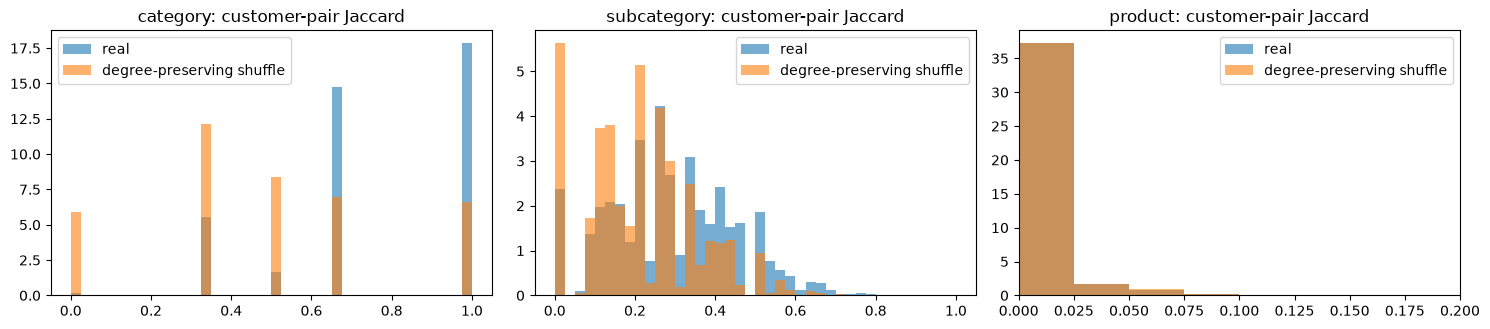

,category,subcategory,product
real mean,0.7597,0.2891,0.0033
real median,0.6667,0.2857,0.0000
shuffled mean,0.4870,0.2099,0.0034
ratio real/shuffled,1.5600,1.3772,0.9743
% pairs with J=0,0.0039,0.0593,0.9297


In [ ]:
rng = np.random.default_rng(SEED)
def jaccard_sample(e, item_col, n_pairs=20000, rng=rng):
    nb = e.groupby('cust_id')[item_col].apply(frozenset)
    ids = nb.index.values
    a, b = rng.choice(ids, n_pairs), rng.choice(ids, n_pairs)
    m = a != b
    return np.array([len(nb[x] & nb[y]) / len(nb[x] | nb[y]) for x, y in zip(a[m], b[m])])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
jac_summary = {}
for ax, (name, col) in zip(axes, LEVELS.items()):
    e = edges[name][['cust_id', col]]
    real = jaccard_sample(e, col)
    shuf = e.copy(); shuf[col] = rng.permutation(shuf[col].values); shuf = shuf.drop_duplicates()
    null = jaccard_sample(shuf, col)
    jac_summary[name] = {'real mean': real.mean(), 'real median': np.median(real), 'shuffled mean': null.mean(),
                         'ratio real/shuffled': real.mean()/max(null.mean(), 1e-9), '% pairs with J=0': (real==0).mean()}
    bins = np.linspace(0, 1, 41)
    ax.hist(real, bins=bins, alpha=.6, density=True, label='real'); ax.hist(null, bins=bins, alpha=.6, density=True, label='degree-preserving shuffle')
    ax.set_title(f'{name}: customer-pair Jaccard'); ax.legend()
    if name == 'product': ax.set_xlim(0, .2)
plt.tight_layout(); plt.show()
pd.DataFrame(jac_summary).round(4)

**Insight (Jaccard, first pass).** Product level: real mean Jaccard 0.0033 vs shuffled 0.0034, a ratio of **0.97**, and 93% of customer pairs share *no* product. Beyond popularity there is essentially no product co-preference signal. Sub-category: 0.29 vs 0.21 (1.38×). Category: 1.56×.

**But my null is flawed at dense levels:** permuting the item column creates duplicate (customer, item) pairs, and dropping them *lowers* degrees in the null graph. That biases the null's Jaccard downward and inflates the ratio, most at category level (85% dense), somewhat at sub-category level, and negligibly at product level. *Fix:* a proper degree-preserving null via random **double-edge swaps** (u1–i1, u2–i2 → u1–i2, u2–i1, rejected if they create a duplicate), which keeps every degree exactly.

In [ ]:
def edge_swap_null(e, item_col, n_swaps_per_edge=10, rng=np.random.default_rng(SEED)):
    u = e['cust_id'].to_numpy().copy(); it = e[item_col].to_numpy().copy()
    present = set(zip(u, it)); E = len(u); done = 0
    for _ in range(n_swaps_per_edge * E):
        a, b = rng.integers(E, size=2)
        if u[a] == u[b] or it[a] == it[b]: continue
        if (u[a], it[b]) in present or (u[b], it[a]) in present: continue
        present -= {(u[a], it[a]), (u[b], it[b])}; present |= {(u[a], it[b]), (u[b], it[a])}
        it[a], it[b] = it[b], it[a]; done += 1
    out = pd.DataFrame({'cust_id': u, item_col: it})
    return out, done

rows = {}
for name, col in LEVELS.items():
    e = edges[name][['cust_id', col]]
    null_e, done = edge_swap_null(e, col)
    assert (null_e.groupby('cust_id').size().sort_index().values == e.groupby('cust_id').size().sort_index().values).all()
    assert (null_e.groupby(col).size().sort_index().values == e.groupby(col).size().sort_index().values).all()
    real = jaccard_sample(e, col, rng=np.random.default_rng(1)); null = jaccard_sample(null_e, col, rng=np.random.default_rng(1))
    rows[name] = {'accepted swaps': done, 'real mean J': real.mean(), 'null mean J': null.mean(), 'ratio': real.mean()/null.mean(),
                  'real 90th pct': np.quantile(real, .9), 'null 90th pct': np.quantile(null, .9)}
pd.DataFrame(rows).round(4)

,category,subcategory,product
accepted swaps,140.0000,12886.0000,78556.0000
real mean J,0.7575,0.2887,0.0036
null mean J,0.7589,0.2881,0.0035
ratio,0.9982,1.0020,1.0435
real 90th pct,1.0000,0.5000,0.0000
null 90th pct,1.0000,0.5000,0.0000


**Insight (Jaccard, corrected null). This is the most important result so far.** With an exact degree-preserving null, real and random neighbourhood overlap are **identical at every level** (ratio 1.00 / 1.00 / 1.04, same 90th percentiles). The first pass's 1.38× at sub-category level was entirely an artefact of the biased null. The asserts confirm that customer and item degrees are preserved exactly.

*Meaning:* once you know how many sub-categories a customer buys and how popular each sub-category is, **who buys what together looks random**. That is the signature of a synthetic or independently-sampled dataset. Mean Jaccard is a coarse statistic, though, so before concluding I check (1) pairwise item associations (lift) and (2) temporal persistence, which is what a next-period model would actually exploit.

**What:** sub-category co-occurrence **lift** = P(a,b) / (P(a)P(b)), computed over (i) customer baskets (all-time sets) and (ii) order baskets. I also estimate how far lift can drift by chance: the same lift matrix on the edge-swap null graph.

**Why:** lift ≠ 1 for specific pairs would show item–item structure that a 2-hop GNN path (item → customer → item) could exploit, even when the global Jaccard looks random.

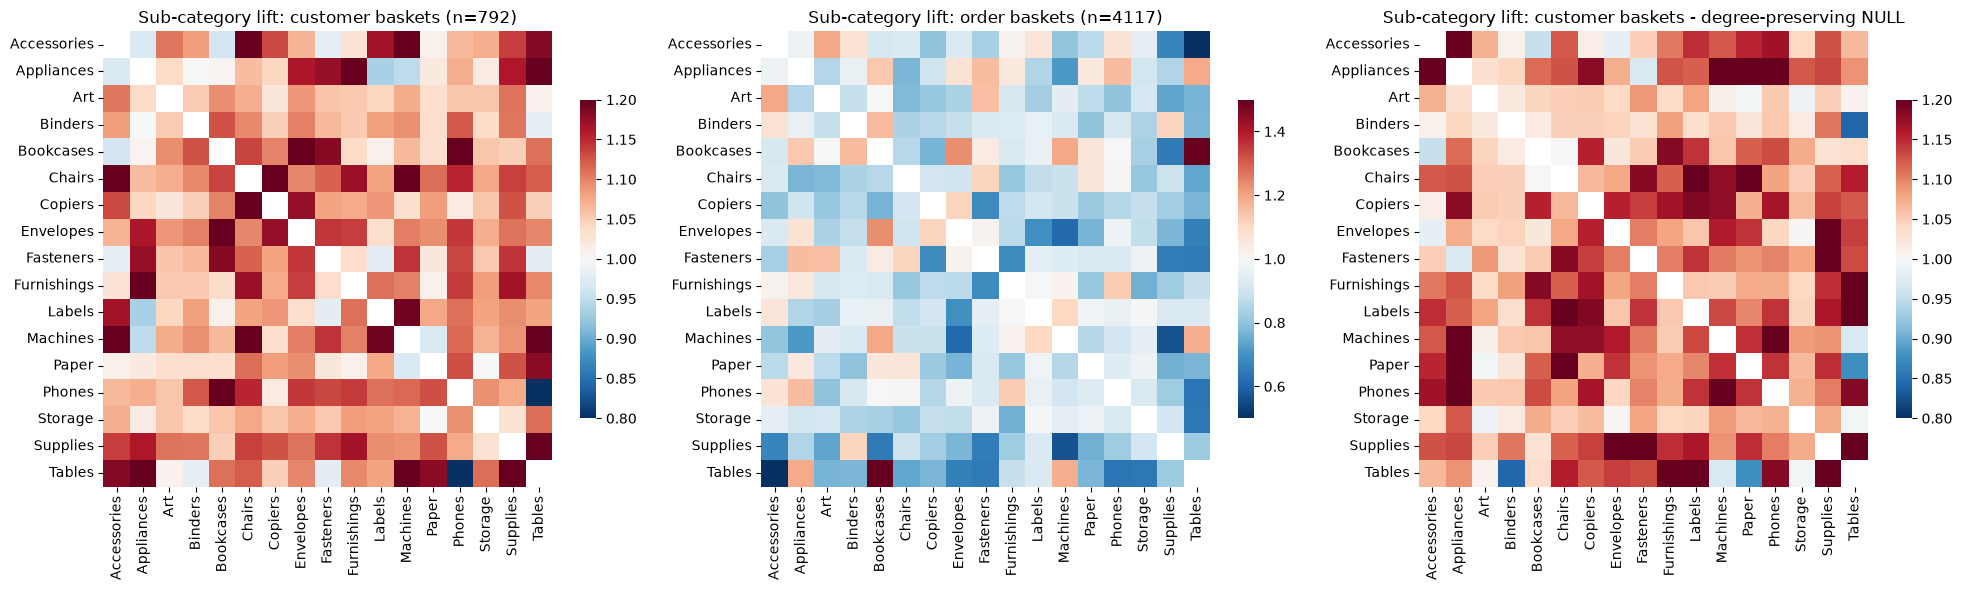

customer  lift: mean 1.087  std 0.077  min 0.66  max 1.31
order     lift: mean 0.902  std 0.156  min 0.32  max 1.52
null      lift: mean 1.096  std 0.078  min 0.84  max 1.35


In [ ]:
subcat_names = df.drop_duplicates('subcat_id').set_index('subcat_id')['Sub-Category'].sort_index()
K = len(subcat_names)

def lift_matrix(baskets_df, key):
    X = pd.crosstab(baskets_df[key], baskets_df['subcat_id']).clip(upper=1).reindex(columns=range(K), fill_value=0).values.astype(float)
    n = len(X); p = X.mean(0); co = (X.T @ X) / n
    L = co / np.outer(p, p); np.fill_diagonal(L, np.nan)
    return L, n

L_cust, n_c = lift_matrix(df[['cust_id','subcat_id']], 'cust_id')
L_order, n_o = lift_matrix(df[['Order ID','subcat_id']], 'Order ID')
null_e, _ = edge_swap_null(edges['subcategory'][['cust_id','subcat_id']], 'subcat_id', rng=np.random.default_rng(7))
L_null, _ = lift_matrix(null_e, 'cust_id')

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, L, title in zip(axes, [L_cust, L_order, L_null], [f'customer baskets (n={n_c})', f'order baskets (n={n_o})', 'customer baskets - degree-preserving NULL']):
    sns.heatmap(L, ax=ax, cmap='RdBu_r', center=1, vmin=0.5 if 'order' in title else 0.8, vmax=1.5 if 'order' in title else 1.2,
                xticklabels=subcat_names.values, yticklabels=subcat_names.values, cbar_kws={'shrink': .7})
    ax.set_title('Sub-category lift: ' + title)
plt.tight_layout(); plt.show()
off = ~np.eye(K, dtype=bool)
for nm, L in [('customer', L_cust), ('order', L_order), ('null', L_null)]:
    v = L[off]; print(f'{nm:9s} lift: mean {np.nanmean(v):.3f}  std {np.nanstd(v):.3f}  min {np.nanmin(v):.2f}  max {np.nanmax(v):.2f}')

**Insight (lift).** The customer-basket heatmap looks like the degree-preserving null: same mean (1.087 vs 1.096) and same spread (std 0.077 vs 0.078). The values sit slightly above 1 because heavy buyers co-occur with everything, not because of real pairings. No block structure shows up either (e.g. no Furniture or Technology clusters). Order-level lift averages *below* 1 (0.90) because orders are small (about 2 lines), and an order with one sub-category cannot contain another. The strongest order-level pairs (max 1.52) come from small cells and are not consistent with the customer view.

*Conclusion so far:* **no item–item co-preference structure beyond popularity.** The last test is the one the task really depends on: **temporal persistence**. Does buying sub-category c in t make c more likely in t+1?

**What:** for each consecutive period pair (t, t+1), using customers active in **both** periods (so "did not buy anything" is not mixed in):
- persistence = P(buy c in t+1 | bought c in t)
- baseline = P(buy c in t+1 | did *not* buy c in t)
- the same contrast with **full history** (bought c at any time ≤ t), closer to what the models will see

Also the target sparsity: how many customers are evaluable per t+1 (active in t+1 *and* seen before), and the mean number of positive labels each.

**Why:** persistence > baseline means "repeat-last-period" is a strong baseline, and a GNN must beat it. If persistence ≈ baseline, history carries little signal beyond popularity.

In [ ]:
def persistence(period_col, item_col):
    periods = sorted(df[period_col].unique())
    sets = df.groupby([period_col, 'cust_id'])[item_col].apply(set)
    hist = {}            # cust -> set of items bought up to and including t
    agg = dict(pers_n=0, pers_k=0, base_n=0, base_k=0, hp_n=0, hp_k=0, hb_n=0, hb_k=0)
    eval_custs, pos_per_cust = [], []
    n_items = df[item_col].nunique()
    for t, t1 in zip(periods[:-1], periods[1:]):
        cur = sets.loc[t].to_dict()
        for c, s in cur.items(): hist.setdefault(c, set()).update(s)
        nxt = sets.loc[t1].to_dict()
        ev = [c for c in nxt if c in hist]                # active in t+1 and seen before
        eval_custs.append(len(ev)); pos_per_cust += [len(nxt[c]) for c in ev]
        for c in ev:
            y, h = nxt[c], hist[c]
            agg['hp_n'] += len(h);           agg['hp_k'] += len(h & y)
            agg['hb_n'] += n_items - len(h); agg['hb_k'] += len(y - h)
            if c in cur:
                x = cur[c]
                agg['pers_n'] += len(x);           agg['pers_k'] += len(x & y)
                agg['base_n'] += n_items - len(x); agg['base_k'] += len(y - x)
    r = lambda k, n: agg[k]/max(agg[n], 1)
    return {'P(c|c in t)': r('pers_k','pers_n'), 'P(c|c not in t)': r('base_k','base_n'),
            'lift last-period': r('pers_k','pers_n')/r('base_k','base_n'),
            'P(c|c in history)': r('hp_k','hp_n'), 'P(c|c not in history)': r('hb_k','hb_n'),
            'lift history': r('hp_k','hp_n')/r('hb_k','hb_n'),
            'pairs active t & t+1': agg['pers_n']>0 and None,
            'eval custs / period (mean)': np.mean(eval_custs), 'eval custs / period (min)': np.min(eval_custs),
            'positives / eval cust (mean)': np.mean(pos_per_cust), 'positives / eval cust (median)': np.median(pos_per_cust)}

res = {}
for per in ['month', 'quarter']:
    for name in ['category', 'subcategory', 'product']:
        res[f'{per} | {name}'] = persistence(per, LEVELS[name])
pers_df = pd.DataFrame(res).drop(index='pairs active t & t+1')
pers_df.round(3)

,month | category,month | subcategory,month | product,quarter | category,quarter | subcategory,quarter | product
P(c|c in t),0.583,0.145,0.000,0.602,0.177,0.001
P(c|c not in t),0.341,0.107,0.001,0.368,0.116,0.001
lift last-period,1.710,1.356,0.000,1.638,1.527,1.059
P(c|c in history),0.527,0.142,0.002,0.551,0.157,0.002
P(c|c not in history),0.332,0.102,0.001,0.352,0.112,0.001
lift history,1.590,1.395,1.469,1.567,1.407,1.490
eval custs / period (mean),65.617,65.617,65.617,180.867,180.867,180.867
eval custs / period (min),1.000,1.000,1.000,21.000,21.000,21.000
positives / eval cust (mean),1.404,1.919,2.095,1.469,2.105,2.330
positives / eval cust (median),1.000,2.000,2.000,1.000,2.000,2.000


**Insight (persistence, raw).** History *does* look predictive: at sub-category level P(c in t+1 | c in history) = 0.14–0.16 vs 0.10–0.11 otherwise (**lift ~1.4**). Last-period-only lift is 1.36 (month) and 1.53 (quarter). Product level is nearly useless: P = 0.002. Target sparsity confirms Phase 1: monthly t+1 has only **~66 evaluable customers per period (min 1)** with ~2 positive sub-categories each; quarterly has **~181 (min 21)**.

**But this raw lift is confounded.** (1) *Item popularity:* items in anyone's history are mostly the popular ones (Art, Storage, Binders), which are also more likely in t+1 for everyone. (2) *Customer volume:* heavy buyers have long histories *and* big t+1 baskets. The Jaccard/lift tests already showed degree-driven effects can mimic structure. *Next:* a controlled test with logistic regression of y = 1[c bought in t+1] on **item fixed effects + customer t+1 basket size + history size + in_history**. The in_history odds ratio is the persistence effect net of popularity and volume. (Diagnostic only: using t+1 basket size is deliberate here and would be leakage in a model.)

In [ ]:
from sklearn.linear_model import LogisticRegression

def controlled_persistence(period_col, item_col):
    periods = sorted(df[period_col].unique()); n_items = df[item_col].nunique()
    sets = df.groupby([period_col, 'cust_id'])[item_col].apply(set)
    hist, cnt, rows = {}, {}, []
    for t, t1 in zip(periods[:-1], periods[1:]):
        for c, s in sets.loc[t].items():
            hist.setdefault(c, set()).update(s)
        for c, y in sets.loc[t1].items():
            if c not in hist: continue
            h = hist[c]
            for i in range(n_items):
                rows.append((i, int(i in h), len(h), len(y), int(i in y)))
    R = pd.DataFrame(rows, columns=['item','in_hist','hist_size','basket_t1','y'])
    X = pd.concat([pd.get_dummies(R['item'], prefix='it', drop_first=True, dtype=float),
                   np.log(R[['hist_size','basket_t1']]), R[['in_hist']]], axis=1)
    m = LogisticRegression(C=1e6, max_iter=5000).fit(X, R['y'])
    coef = dict(zip(X.columns, m.coef_[0]))
    # bootstrap-free uncertainty: refit on 2 halves of periods
    return {'rows': len(R), 'OR in_hist (controlled)': np.exp(coef['in_hist']),
            'OR log basket_t1': np.exp(coef['basket_t1']), 'OR log hist_size': np.exp(coef['hist_size']),
            'raw OR in_hist': (R.query('in_hist==1').y.mean()/(1-R.query('in_hist==1').y.mean())) / (R.query('in_hist==0').y.mean()/(1-R.query('in_hist==0').y.mean()))}

cp = {f'{per} | subcategory': controlled_persistence(per, 'subcat_id') for per in ['month','quarter']}
cp['quarter | category'] = controlled_persistence('quarter', 'cat_id')
pd.DataFrame(cp).round(3)

,month | subcategory,quarter | subcategory,quarter | category
rows,52428.000,46121.000,8139.000
OR in_hist (controlled),1.010,1.014,1.030
OR log basket_t1,3.463,3.523,27.105
OR log hist_size,1.000,0.999,0.978
raw OR in_hist,1.461,1.483,2.262


**Insight (controlled persistence). The raw persistence was almost entirely confounding.** After controlling for item popularity (fixed effects) and the customer's t+1 basket size, the odds ratio for "c is in the customer's history" drops from **1.46–1.48 to 1.01** (sub-category, month and quarter) and from 2.26 to 1.03 at category level. History size adds nothing (OR 1.00). Basket size dominates (OR 3.5 per log unit), which is just "customers who buy more buy more of everything".

Taken with the Jaccard and lift results: **in this dataset, which sub-categories a customer buys next looks like a draw from global popularity, scaled by how much they buy. Their own past choices and their neighbours' choices add almost nothing.** Before I rely on this I want an uncertainty estimate on the OR, since 1.01 might hide a small real effect.

**What:** a 95% interval for the controlled in_history odds ratio via a **customer-cluster bootstrap** (resample customers with replacement, 200 reps; rows of the same customer are correlated, so a naive SE would be too narrow). Sub-category, quarterly.

In [ ]:
def persistence_rows(period_col, item_col):
    periods = sorted(df[period_col].unique()); n_items = df[item_col].nunique()
    sets = df.groupby([period_col, 'cust_id'])[item_col].apply(set)
    hist, rows = {}, []
    for t, t1 in zip(periods[:-1], periods[1:]):
        for c, s in sets.loc[t].items(): hist.setdefault(c, set()).update(s)
        for c, y in sets.loc[t1].items():
            if c in hist:
                h = hist[c]
                rows += [(c, i, int(i in h), np.log(len(h)), np.log(len(y)), int(i in y)) for i in range(n_items)]
    return pd.DataFrame(rows, columns=['cust','item','in_hist','log_hist','log_basket','y'])

R = persistence_rows('quarter', 'subcat_id')
Xfull = pd.concat([pd.get_dummies(R['item'], prefix='it', drop_first=True, dtype=float), R[['log_hist','log_basket','in_hist']]], axis=1).values
yfull = R['y'].values
cust_rows = R.groupby('cust').indices; custs = np.array(list(cust_rows))
boot_rng = np.random.default_rng(SEED); ors = []
t0 = time.time()
for b in range(200):
    pick = boot_rng.choice(custs, len(custs))
    idx = np.concatenate([cust_rows[c] for c in pick])
    m = LogisticRegression(C=1e6, max_iter=3000).fit(Xfull[idx], yfull[idx])
    ors.append(np.exp(m.coef_[0][-1]))
ors = np.array(ors)
print(f'controlled OR(in_hist), sub-category, quarterly: median {np.median(ors):.3f}, 95% CI [{np.quantile(ors,.025):.3f}, {np.quantile(ors,.975):.3f}]  ({time.time()-t0:.0f}s)')

controlled OR(in_hist), sub-category, quarterly: median 1.014, 95% CI [0.942, 1.093]  (14s)


**Insight (bootstrap).** Controlled OR = 1.014, **95% CI [0.94, 1.09]**. The interval includes 1, so there is no detectable persistence effect once popularity and basket size are accounted for. An effect larger than about +9% in odds is ruled out.

### Phase 2 summary and recommendation

| Gate | Category (3) | **Sub-category (17)** | Product (1,810) |
|---|---|---|---|
| density | 85%, near-complete ❌ | 40% ✅ | 0.6% |
| connectivity / degree-1 customers | 1 comp / 7% | 1 comp / 1.8% ✅ | 1 comp / 1.5% |
| 5-core / 10-core customers kept | 0 / 0 | 81% / 16% | 58% / **0%** ❌ |
| repeat-edge rate | 70% | 29% | **0.4%** ❌ |
| Jaccard real ÷ degree-preserving null | 1.00 | 1.00 | 1.04 |
| raw → controlled persistence OR | 2.26 → 1.03 | 1.48 → **1.01** [0.94, 1.09] | — |

**Recommendation: Sub-category level with quarterly periods.**
- Category is too dense to be a ranking problem. Product is too sparse: no repeats, an empty 10-core, and ~2 positives among 1,810 candidates.
- Quarterly periods give ~181 evaluable customers per target period (min 21) vs ~66 (min 1) monthly. Monthly val/test windows would be noisy. With 16 quarters, a whole-period 70/15/15 split is about 11 / 2 / 3 quarters (or 10/3/3).

**Expectation to set now:** the graph shows **no collaborative or temporal signal beyond item popularity and customer volume** (Jaccard = null, lift = null, controlled persistence OR ≈ 1). The data looks synthetically generated with independent draws. Per-customer ranking ignores basket size, so I expect **popularity to be close to optimal** and GCN/GAT to at best match it. That would be a valid, explainable finding: message passing cannot recover structure the data does not contain. The pipeline is still worth running as planned, because it demonstrates this rigorously.

## Research questions and hypotheses (stated before any modelling)

The user-facing question is a **shopping** one: *for each sub-category, what percentage of customers will buy it next quarter, and which customers?* The model output, a customer × sub-category probability matrix P, answers both. Averaging a column of P over all eligible customers gives the **expected % of customers buying that sub-category next quarter**, and the row ranking says **who** is most likely to buy it.

| ID | Hypothesis | How it is tested |
|---|---|---|
| **H1** | Graph structure (GCN/GAT) beats non-graph baselines | test-set Recall@10, NDCG@10 and PR-AUC; 5 seeds; gap must exceed seed std |
| **H2** | GAT's learned neighbour weights beat GCN's fixed 1/√(d_i d_j) weights, especially for low-degree customers | same, plus a split by customer degree |
| **H3** | A customer's own history raises their probability of rebuying a sub-category | Phase 2 controlled odds ratio (already ≈ 1.01, CI [0.94, 1.09]: **not supported**) |
| **H4** | The % of customers buying each sub-category next quarter can be predicted accurately | predicted vs actual % per sub-category on test quarters (calibration error) |
| **H5** | Customer segment (Consumer / Corporate / Home Office) changes *what* people buy | χ² test of segment × sub-category |
| **H6** | Purchasing is seasonal: Q4 has a higher % of customers buying | % active by quarter-of-year (χ²) |

*Prior from Phase 2:* H1 and H2 are unlikely to hold because no structure beyond popularity was found. H4 should hold reasonably well because popularity is stable.